# 04 · Volume Anomaly: the 2016 Slowdown

**Question:** annual volume stopped growing in 2016. When did it start, how large was the real decline, and how long did it last?

**Bottom line:** after a **one-off spike in March 2016 (\$949M)**, funded volume was **down year-over-year for 10 straight months (Jul-2016 to Apr-2017)** and recovered from May 2017. The headline **−43% month-over-month drop in April 2016 is a base effect**: year-over-year, April was down only 0.4%. Decomposing H2-2016 vs. H2-2015 (−21.9% funded), **applications rose 54% while the approval rate fell 45%**, so the drop came from the approval side, not from demand. A **mix-rate decomposition** by credit score band shows the approval drop was **not** caused by weaker applicants: **98%** of the 5.84 pp decline comes from lower approval rates *within* the same score bands. The timing coincides with Lending Club's May 2016 governance crisis (CEO resignation, investors pulling back funding).

**Framework used:** validate → put in context (base effect, seasonality, baseline) → decompose → find drivers.

In [1]:
import sys
sys.path.append("../src")

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from lending_db import get_connection, IMAGE_DIR

con = get_connection()
pd.set_option("display.max_columns", None)
plt.rcParams.update({"figure.figsize": (10, 5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

## 1. Monthly funded volume, 2015–2017
`DATE_TRUNC('month', ...)` keeps year and month together (`MONTH()` alone would merge Jan-2015, Jan-2016 and Jan-2017).

In [2]:
monthly = con.sql("""
SELECT DATE_TRUNC('month', issue_date)  AS issue_month,
       COUNT(*)                         AS n_loans,
       SUM(funded_amnt) / 1000000       AS funded_mm
FROM loans_clean
WHERE issue_date >= '2015-01-01' AND issue_date < '2018-01-01'
GROUP BY issue_month
ORDER BY issue_month
""").df()

baseline_2015 = monthly.loc[monthly["issue_month"].dt.year == 2015, "funded_mm"].mean()
print(f"2015 average: ${baseline_2015:,.0f}M per month")

2015 average: $535M per month


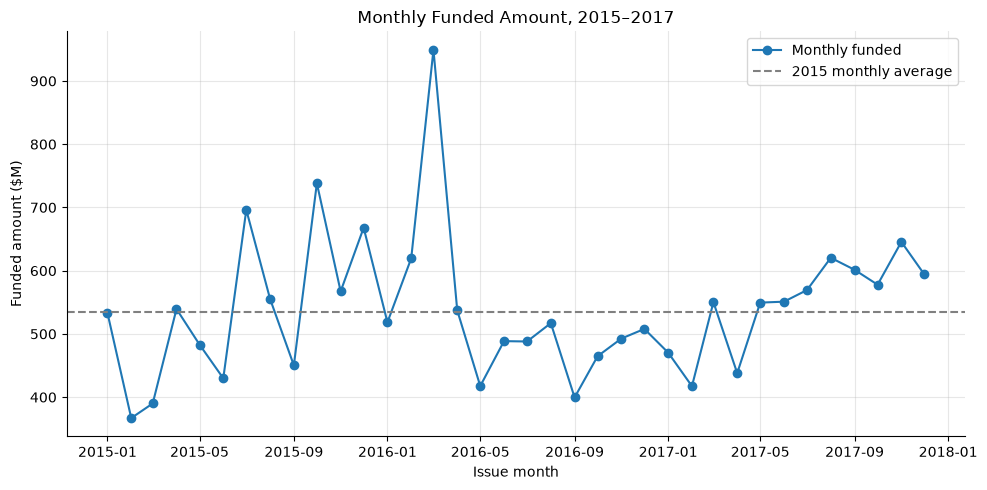

In [3]:
fig, ax = plt.subplots()
ax.plot(monthly["issue_month"], monthly["funded_mm"], marker="o", label="Monthly funded")
ax.axhline(baseline_2015, linestyle="--", color="gray", label="2015 monthly average")
ax.set_title("Monthly Funded Amount, 2015–2017")
ax.set_xlabel("Issue month")
ax.set_ylabel("Funded amount ($M)")
ax.legend()
fig.tight_layout()
fig.savefig(IMAGE_DIR / "monthly_funded_2015_2017.png", dpi=150)
plt.show()

## 2. Month-over-month change with `LAG`
Ratios are computed on unrounded amounts; rounding happens only for display.

In [4]:
mom = con.sql("""
WITH monthly AS (
    SELECT DATE_TRUNC('month', issue_date) AS issue_month,
           SUM(funded_amnt) / 1000000      AS funded_mm
    FROM loans_clean
    WHERE issue_date >= '2015-01-01' AND issue_date < '2018-01-01'
    GROUP BY issue_month
)
SELECT issue_month,
       ROUND(funded_mm, 1)                                                     AS funded_mm,
       ROUND(LAG(funded_mm) OVER (ORDER BY issue_month), 1)                    AS prev_month_mm,
       ROUND(funded_mm / LAG(funded_mm) OVER (ORDER BY issue_month) - 1, 4)    AS mom_change
FROM monthly
ORDER BY mom_change
LIMIT 5
""").df()
mom

,issue_month,funded_mm,prev_month_mm,mom_change
0,2016-04-01,537.3,949.4,-0.4341
1,2015-02-01,366.9,533.1,-0.3118
2,2015-11-01,567.2,738.2,-0.2316
3,2016-09-01,399.5,517.1,-0.2273
4,2016-01-01,518.4,667.9,-0.2238


The largest MoM drops all follow an unusually **high** prior month: Apr-2016 follows the March spike, and Nov-2015 follows October. In 2015, peaks cluster in **quarter-start months (Apr, Jul, Oct)**, a seasonal pattern whose cause (marketing cadence, investor funding cycles, business days) still needs to be confirmed. MoM is therefore noisy; the real question is the level versus a stable baseline.

## 3. Real decline vs. 2015 baseline

In [5]:
monthly["vs_2015_avg"] = monthly["funded_mm"] / baseline_2015 - 1
period = monthly["issue_month"].between("2016-05-01", "2017-04-01")
trough = monthly.loc[period]
print(f"May-2016 to Apr-2017: ${trough['funded_mm'].min():,.0f}M – ${trough['funded_mm'].max():,.0f}M per month")
print(f"Average gap vs. 2015 run-rate: {trough['vs_2015_avg'].mean():.1%}")
monthly.assign(funded_mm=monthly["funded_mm"].round(1), vs_2015_avg=monthly["vs_2015_avg"].round(3))

May-2016 to Apr-2017: $400M – $550M per month
Average gap vs. 2015 run-rate: -11.9%


,issue_month,n_loans,funded_mm,vs_2015_avg
0,2015-01-01,35107,533.1,-0.003
1,2015-02-01,23770,366.9,-0.314
2,2015-03-01,25400,390.0,-0.271
3,2015-04-01,35427,539.4,0.009
4,2015-05-01,31913,483.2,-0.097
5,2015-06-01,28485,429.8,-0.196
6,2015-07-01,45962,696.2,0.302
7,2015-08-01,35886,555.3,0.038
8,2015-09-01,28641,450.2,-0.158
9,2015-10-01,48631,738.2,0.380


## 4. Year-over-year change with `LAG(x, 12)`
Comparing each month with the same month last year removes seasonality. `LAG(x, 12)` counts rows, so it assumes no missing months (true here).

In [6]:
yoy = con.sql("""
WITH monthly AS (
    SELECT DATE_TRUNC('month', issue_date) AS issue_month,
           SUM(funded_amnt) / 1000000      AS funded_mm
    FROM loans_clean
    WHERE issue_date >= '2015-01-01' AND issue_date < '2018-01-01'
    GROUP BY issue_month
)
SELECT issue_month,
       ROUND(funded_mm, 1)                                                      AS funded_mm,
       ROUND(LAG(funded_mm, 12) OVER (ORDER BY issue_month), 1)                 AS last_year_mm,
       ROUND(funded_mm / LAG(funded_mm, 12) OVER (ORDER BY issue_month) - 1, 4) AS yoy_change
FROM monthly
ORDER BY issue_month
""").df()

yoy = yoy.dropna()          # 2015 has no prior year to compare against
negative = yoy[yoy["yoy_change"] < 0]
print("Months with negative YoY:", ", ".join(negative["issue_month"].dt.strftime("%b-%Y")))
yoy

Months with negative YoY: Jan-2016, Apr-2016, May-2016, Jul-2016, Aug-2016, Sep-2016, Oct-2016, Nov-2016, Dec-2016, Jan-2017, Feb-2017, Mar-2017, Apr-2017


,issue_month,funded_mm,last_year_mm,yoy_change
12,2016-01-01,518.4,533.1,-0.0276
13,2016-02-01,619.4,366.9,0.6883
14,2016-03-01,949.4,390.0,1.4343
15,2016-04-01,537.3,539.4,-0.0039
16,2016-05-01,417.5,483.2,-0.1359
17,2016-06-01,488.6,429.8,0.1369
18,2016-07-01,488.0,696.2,-0.2991
19,2016-08-01,517.1,555.3,-0.0689
20,2016-09-01,399.5,450.2,-0.1127
21,2016-10-01,464.8,738.2,-0.3704


* **Apr-2016:** −43.4% MoM but only **−0.4% YoY**. April itself was normal; the MoM drop is a **base effect** from the March spike.
* **Jul-2016 to Apr-2017:** **10 consecutive months** of negative YoY, ranging from −7% to −42%. This is the real slowdown.
* YoY removes **seasonality** but not **one-off spikes**: Mar-2017 shows −42% YoY only because it is compared with the Mar-2016 spike. No single comparison is enough.

## 5. Decomposition: H2-2016 vs. H2-2015
`funded volume = applications × approval rate × average loan size`

Same-length windows (Jul–Dec) avoid the March spike and seasonality. Applications = approved + rejected; rejections are dated by application date, approvals by issue date, so the split is approximate.

In [7]:
decomp = con.sql("""
WITH a AS (
    SELECT DATE_TRUNC('month', issue_date) AS month,
           COUNT(*)                        AS n_accepted,
           SUM(funded_amnt)                AS funded
    FROM loans_clean
    GROUP BY month
),
r AS (
    SELECT DATE_TRUNC('month', "Application Date") AS month,
           COUNT(*)                                AS n_rejected
    FROM rejected
    GROUP BY month
),
m AS (
    SELECT a.month, a.n_accepted, r.n_rejected, a.funded,
           CASE WHEN a.month BETWEEN '2015-07-01' AND '2015-12-01' THEN 'H2-2015'
                WHEN a.month BETWEEN '2016-07-01' AND '2016-12-01' THEN 'H2-2016'
           END AS period
    FROM a
    JOIN r ON a.month = r.month
)
SELECT period,
       SUM(n_accepted + n_rejected)                                    AS applications,
       SUM(n_accepted) * 1.0 / SUM(n_accepted + n_rejected)            AS approval_rate,
       SUM(funded) / SUM(n_accepted)                                   AS avg_loan_size,   -- weighted, not an average of monthly averages
       SUM(funded) / 1000000                                           AS funded_mm
FROM m
WHERE period IS NOT NULL
GROUP BY period
ORDER BY period
""").df().set_index("period").T

decomp["change"] = decomp["H2-2016"] / decomp["H2-2015"] - 1
decomp.round(4)

period,H2-2015,H2-2016,change
applications,1.871026e+06,2.879775e+06,0.5391
approval_rate,1.288000e-01,7.040000e-02,-0.4536
avg_loan_size,1.525022e+04,1.416079e+04,-0.0714
funded_mm,3.675196e+03,2.869912e+03,-0.2191


In [8]:
# Check: the component changes must multiply out to the total change
c = decomp["change"]
implied = (1 + c["applications"]) * (1 + c["approval_rate"]) * (1 + c["avg_loan_size"]) - 1
print(f"Implied funded change: {implied:.1%}   Actual: {c['funded_mm']:.1%}")

Implied funded change: -21.9%   Actual: -21.9%


| Driver | Change | Effect on volume |
|---|---:|---|
| Applications | **+53.9%** | ⬆ Demand was not the problem |
| Approval rate | **−45.4%** | ⬇⬇ **Main driver** |
| Average loan size | −7.1% | ⬇ Minor |
| **Funded volume** | **−21.9%** | |

The data shows **that** the approval rate fell, not **why**. Three hypotheses: **policy tightening**, a **weaker applicant mix**, or an **investor funding constraint**.

## 6. Mix vs. rate: did applicants get worse?
`applications` stacks approved loans (FICO) and declined applications (`Risk_Score`) with `UNION ALL`. Within each score band, compare the **share** of applicants (mix) and the **approval rate** (rate).

In [9]:
bands = con.sql("""
WITH labeled AS (
    SELECT CASE WHEN app_month BETWEEN '2015-07-01' AND '2015-12-01' THEN 'H2-2015'
                WHEN app_month BETWEEN '2016-07-01' AND '2016-12-01' THEN 'H2-2016'
           END AS period,
           CASE WHEN score IS NULL THEN '0. Missing'
                WHEN score < 600   THEN '1. <600'
                WHEN score < 660   THEN '2. 600-659'
                WHEN score < 700   THEN '3. 660-699'
                WHEN score < 750   THEN '4. 700-749'
                ELSE                    '5. 750+'
           END AS score_band,
           approved
    FROM applications
)
SELECT period,
       score_band,
       COUNT(*)                                                 AS n_apps,
       COUNT(*) * 1.0 / SUM(COUNT(*)) OVER (PARTITION BY period) AS share,   -- share within each period
       AVG(approved)                                            AS approval_rate
FROM labeled
WHERE period IS NOT NULL
GROUP BY period, score_band
ORDER BY score_band, period
""").df()

assert bands.groupby("period")["share"].sum().round(6).eq(1).all(), "shares must sum to 100% per period"
wide = bands.pivot(index="score_band", columns="period", values=["share", "approval_rate"])
wide.round(4)

share         approval_rate        
period     H2-2015 H2-2016       H2-2015 H2-2016
score_band                                      
0. Missing  0.8119  0.6778        0.0000  0.0000
1. <600     0.0115  0.0756        0.0000  0.0000
2. 600-659  0.0251  0.0966        0.0000  0.0000
3. 660-699  0.0960  0.0931        0.8441  0.4736
4. 700-749  0.0455  0.0433        0.8573  0.4922
5. 750+     0.0100  0.0136        0.8738  0.3632

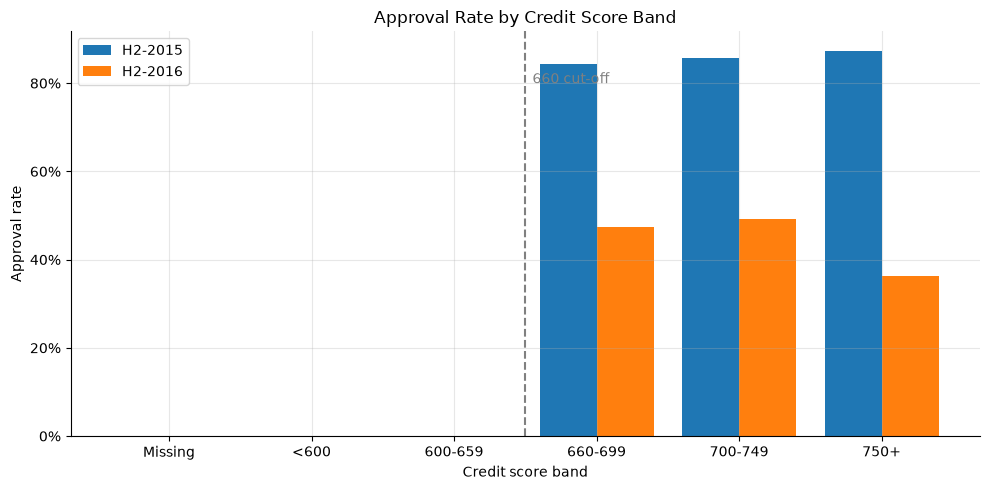

In [10]:
fig, ax = plt.subplots()
x = range(len(wide))
ax.bar([i - 0.2 for i in x], wide["approval_rate"]["H2-2015"], width=0.4, label="H2-2015")
ax.bar([i + 0.2 for i in x], wide["approval_rate"]["H2-2016"], width=0.4, label="H2-2016")
ax.set_xticks(list(x), [b[3:] for b in wide.index])
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_title("Approval Rate by Credit Score Band")
ax.set_xlabel("Credit score band")
ax.set_ylabel("Approval rate")
ax.axvline(2.5, linestyle="--", color="gray")
ax.annotate("660 cut-off", xy=(2.55, 0.8), color="gray")
ax.legend()
fig.tight_layout()
fig.savefig(IMAGE_DIR / "approval_rate_by_score_band.png", dpi=150)
plt.show()

* **Below 660, approval is 0% in both periods**: a hard **knockout rule**.
* ~80% of declined applications have **no score at all**: they were rejected before a credit pull (basic eligibility), so missing ≠ low score.
* The below-660 share jumped (3.7% → 17.2%), but it mostly replaced *unscored* applicants, who are also never approved. The share **above 660 barely moved (15.2% → 15.0%)**.
* Above 660, the approval rate **nearly halved in every band**, and fell most for **750+ (87% → 36%)**.

### Decomposition
`approval rate = Σ share × band rate`. The counterfactual applies H2-2016's mix to H2-2015's band rates.

In [11]:
s15, s16 = wide["share"]["H2-2015"], wide["share"]["H2-2016"]
r15, r16 = wide["approval_rate"]["H2-2015"], wide["approval_rate"]["H2-2016"]

actual_15      = (s15 * r15).sum()
counterfactual = (s16 * r15).sum()   # 2016 applicants, 2015 approval standards
actual_16      = (s16 * r16).sum()

total = actual_16 - actual_15
mix   = counterfactual - actual_15
rate  = actual_16 - counterfactual

print(f"H2-2015 approval rate: {actual_15:.2%}")
print(f"H2-2016 approval rate: {actual_16:.2%}")
print(f"total change:          {total * 100:+.2f} pp")
print(f"  mix effect:          {mix * 100:+.2f} pp  ({mix / total:.0%})")
print(f"  rate effect:         {rate * 100:+.2f} pp  ({rate / total:.0%})")

H2-2015 approval rate: 12.88%
H2-2016 approval rate: 7.04%
total change:          -5.84 pp
  mix effect:          -0.12 pp  (2%)
  rate effect:         -5.73 pp  (98%)


**Result:** the applicant-quality hypothesis is **rejected**. Only **2%** of the 5.84 pp drop comes from the mix; **98%** comes from lower approval rates *within* the same score bands.

## 7. Next steps
1. Separate **policy tightening** from a **funding constraint**. The steepest drop among the *best* applicants (750+) is unusual for a credit-policy change, which normally cuts marginal borrowers first; this points toward funding / volume caps after the May 2016 investor pullback.
2. Check whether `Risk_Score` (declined) and FICO (approved) are on the same scale; the band comparison assumes they are comparable.